# Modelo — predicción de pobreza multidimensional por hogar
## ETL Tercera Entrega · Notebook 04

En este notebook entrenamos el modelo que predice si un hogar es pobre según el IPM (`pobre`). Los datos no los unimos aquí: salen de la vista `vw_dataset_prediccion` que deja el DAG (tarea `load_hogar`), o de `dataset_prediccion.parquet`, que es esa misma vista exportada por `store_hogar`. Eso quiere decir que el IPM, el CSV de viviendas y el contexto departamental ya vienen unidos por hogar y ya pasaron por Great Expectations.

La idea de uso es estimar si un hogar tiene pobreza multidimensional a partir de lo que se sabe de su vivienda y del contexto de su departamento, sin tener que aplicar los 15 indicadores completos de la encuesta. Ese es el caso que después simulamos con Kafka: llega un hogar con esas variables, el consumer le calcula la probabilidad y el dashboard la muestra.

Las variables de vivienda (pisos, paredes, acueducto y alcantarillado) son parte de los insumos de cuatro de los 15 indicadores del IPM, así que el modelo no parte de cero. Lo dejamos escrito en las limitaciones del final para que no parezca que descubrimos algo que en realidad ya estaba en la definición del índice.

Hay tres cosas que hicimos distinto a la primera versión del modelo (la que estaba en `super_merge`). El umbral de decisión se escoge con un conjunto de validación y no con el de prueba. Todo el preprocesamiento vive dentro del pipeline que se guarda, así el consumer no tiene que repetir nada a mano. Y el archivo del modelo queda acompañado de las versiones de las librerías y de las métricas.

## Paso 0 — Dependencias

In [20]:
!pip install -q scikit-learn pandas pyarrow matplotlib joblib sqlalchemy psycopg2-binary

## Paso 1 — Configuración

En Colab guardamos en Drive y fuera de Colab en una carpeta local, igual que en los otros notebooks. `SRC` es la carpeta donde queda el archivo con la función de preparación (Paso 4), que el consumer de Kafka tiene que importar igual que este notebook.

In [21]:
import os, sys, io, json, shutil, hashlib, platform, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/My Drive/Colab Notebooks/etl_proyecto"
except Exception:
    BASE = os.environ.get("ETL_BASE", "./etl_proyecto")

REPORTES = f"{BASE}/reports"
MODELOS = f"{BASE}/models"
SRC = "./src"
for carpeta in (REPORTES, MODELOS, SRC):
    os.makedirs(carpeta, exist_ok=True)

RUTA_PARQUET = f"{BASE}/dataset_prediccion.parquet"   # lo escribe store_hogar
VISTA = "vw_dataset_prediccion"
SEMILLA = 42


def secreto(nombre):
    # primero variable de entorno, después secretos de colab
    if nombre in os.environ:
        return os.environ[nombre]
    try:
        from google.colab import userdata
        return userdata.get(nombre)
    except Exception:
        return None

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Paso 2 — Lectura del dataset

Si hay `DESTINO_URL` leemos la vista directamente de la base donde cargó el DAG. Si no existe, o la base ya no está (por ejemplo, el SQLite de Colab se borra cuando se reinicia el entorno), usamos el parquet que exportó `store_hogar`.

In [22]:
COLS_REQUERIDAS = ["id_hogar", "codigo_departamento", "personas", "fex_c", "ipm", "pobre",
                   "clase", "material_paredes", "material_pisos",
                   "acueducto_vivienda", "alcantarillado_vivienda"]


def leer_dataset():
    url = secreto("DESTINO_URL")
    d, origen = None, None
    if url:
        try:
            from sqlalchemy import create_engine
            d = pd.read_sql_query(f"SELECT * FROM {VISTA}", create_engine(url))
            origen = f"vista {VISTA}"
        except Exception as e:
            print(f"[leer] no se pudo leer la vista ({type(e).__name__}); se usa el parquet")
    if d is None:
        if not os.path.exists(RUTA_PARQUET):
            raise FileNotFoundError(f"No existe {RUTA_PARQUET}. Ejecutar el DAG hasta store_hogar.")
        d = pd.read_parquet(RUTA_PARQUET)
        origen = os.path.basename(RUTA_PARQUET)
    faltan = [c for c in COLS_REQUERIDAS if c not in d.columns]
    if faltan:
        raise KeyError(f"Al dataset le faltan {faltan}. Columnas: {list(d.columns)}")
    print(f"[leer] {origen}: {len(d):,} filas x {d.shape[1]} columnas")
    return d


df = leer_dataset()
df.head()

[leer] dataset_prediccion.parquet: 86,848 filas x 22 columnas


,id_hogar,codigo_departamento,personas,fex_c,ipm,pobre,clase,material_paredes,material_pisos,alcantarillado_vivienda,acueducto_vivienda,sin_acueducto,sin_alcantarillado,pobreza_monetaria,hogares_db,pct_sin_acueducto,pct_sin_alcantarillado,pct_piso_tierra,pct_rural_disperso,ingreso_prom_dpto,pct_ocupados_dpto,pct_educ_superior_dpto
0,8369550-1,13,4,472.131901,0.05,0,1,1,4,1,1,0,0,34.332884,11237.0,26.181937,63.580046,12.031301,14.867949,988212.883182,53.105366,26.592154
1,8369551-1,13,1,308.854319,0.20,0,1,1,4,1,1,0,0,34.332884,11237.0,26.181937,63.580046,12.031301,14.867949,988212.883182,53.105366,26.592154
2,8369552-1,13,5,428.516239,0.15,0,1,1,6,1,1,0,0,34.332884,11237.0,26.181937,63.580046,12.031301,14.867949,988212.883182,53.105366,26.592154
3,8369553-1,13,3,268.976656,0.30,0,1,1,6,1,1,0,0,34.332884,11237.0,26.181937,63.580046,12.031301,14.867949,988212.883182,53.105366,26.592154
4,8369554-1,13,2,353.949442,0.30,0,1,1,4,1,1,0,0,34.332884,11237.0,26.181937,63.580046,12.031301,14.867949,988212.883182,53.105366,26.592154


## Paso 3 — Revisión rápida

Great Expectations ya validó estas tablas dentro del DAG, pero revisamos lo que el modelo necesita de verdad antes de entrenar. Si algo no se cumple, el notebook se detiene.

In [23]:
assert df["id_hogar"].is_unique, "id_hogar repetido"
assert df["pobre"].isin([0, 1]).all(), "pobre debe ser 0 o 1"
assert df[["id_hogar", "fex_c", "personas", "pobre", "codigo_departamento"]].notna().all().all(), "nulos en columnas clave"
assert (df["fex_c"] > 0).all(), "fex_c debe ser positivo"

print(f"Hogares pobres (muestra, sin ponderar): {df['pobre'].mean():.1%}")
print(f"Hogares pobres (ponderado con fex_c):   {np.average(df['pobre'], weights=df['fex_c']):.1%}")

nulos = df.isna().mean().sort_values(ascending=False)
print("\nColumnas con nulos:")
print(nulos[nulos > 0].round(3).to_string() or "ninguna")

Hogares pobres (muestra, sin ponderar): 14.2%
Hogares pobres (ponderado con fex_c):   8.3%

Columnas con nulos:
pct_ocupados_dpto         0.21
ingreso_prom_dpto         0.21
hogares_db                0.21
pct_educ_superior_dpto    0.21
pobreza_monetaria         0.21


## Paso 4 — Preparación de variables (módulo compartido)

El pipeline que guardamos tiene como primer paso una función que arma las variables a partir de las columnas tal como están en la vista: convierte las categóricas a texto (con `nd` cuando falta la respuesta), calcula `sin_acueducto` y `sin_alcantarillado` (en el CSV 1 es sí y 2 es no) y deja los números como `float`. Así el consumer le pasa al modelo el evento tal como llega de Kafka.

Una función dentro de un pipeline de `joblib` se guarda como referencia al módulo donde está definida, no como copia del código. Si la escribiéramos en una celda del notebook quedaría en `__main__` y el consumer no la encontraría al cargar el modelo. Por eso la escribimos en un archivo y la importamos desde ahí; el consumer tiene que importar ese mismo archivo.

Lo que se usa como entrada: el departamento, `personas`, las cuatro variables de vivienda y ocho variables de contexto departamental. Quedan fuera `pobre` (el target), `ipm`, `fex_c` (peso de la encuesta, no una característica del hogar) y `hogares_db`. Tampoco entran `incidencia_ipm` ni `ipm_promedio` del departamento, porque se calculan con el mismo `pobre`.

In [24]:
%%writefile src/features_pobreza.py
"""Preparación de variables del modelo de pobreza.
La usan el notebook 04 (entrenamiento) y el consumer de kafka (inferencia)."""
import pandas as pd

COLS_CONTEXTO = ["pobreza_monetaria", "ingreso_prom_dpto", "pct_ocupados_dpto",
                 "pct_educ_superior_dpto", "pct_sin_acueducto", "pct_sin_alcantarillado",
                 "pct_piso_tierra", "pct_rural_disperso"]

CAT_HOGAR = ["clase", "material_paredes", "material_pisos"]
CAT_DPTO = ["codigo_departamento"]

# columnas que tiene que traer cada evento (ademas del id del hogar)
COLS_ENTRADA = (CAT_DPTO + ["personas"] + CAT_HOGAR
                + ["acueducto_vivienda", "alcantarillado_vivienda"] + COLS_CONTEXTO)

NUM_BASE = ["personas", "sin_acueducto", "sin_alcantarillado"] + COLS_CONTEXTO


def _categoria(serie):
    # codigos numericos del csv como texto; si falta la respuesta queda "nd"
    s = pd.to_numeric(serie, errors="coerce").astype("Int64").astype("string")
    return s.fillna("nd").astype(object)


def _codigo_dpto(serie):
    s = serie.astype("string").str.strip().str.zfill(2)
    return s.fillna("nd").astype(object)


def preparar(df):
    faltan = [c for c in COLS_ENTRADA if c not in df.columns]
    if faltan:
        raise KeyError(f"Al evento le faltan {faltan}")

    d = pd.DataFrame(index=df.index)
    d["codigo_departamento"] = _codigo_dpto(df["codigo_departamento"])
    for c in CAT_HOGAR:
        d[c] = _categoria(df[c])

    d["personas"] = pd.to_numeric(df["personas"], errors="coerce").astype("float64")
    for c in COLS_CONTEXTO:
        d[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")

    # en el csv 1 = si y 2 = no; si falta la respuesta queda nulo
    for nuevo, origen in (("sin_acueducto", "acueducto_vivienda"),
                          ("sin_alcantarillado", "alcantarillado_vivienda")):
        v = pd.to_numeric(df[origen], errors="coerce")
        d[nuevo] = (v == 2).astype("float64").where(v.notna())
    return d

Overwriting src/features_pobreza.py


In [25]:
# se importa desde el archivo, igual que lo hará el consumer
if SRC not in sys.path:
    sys.path.insert(0, os.path.abspath(SRC))
import features_pobreza as fp

print("Columnas de entrada del modelo:", fp.COLS_ENTRADA)
fp.preparar(df[fp.COLS_ENTRADA].head(3)).T

Columnas de entrada del modelo: ['codigo_departamento', 'personas', 'clase', 'material_paredes', 'material_pisos', 'acueducto_vivienda', 'alcantarillado_vivienda', 'pobreza_monetaria', 'ingreso_prom_dpto', 'pct_ocupados_dpto', 'pct_educ_superior_dpto', 'pct_sin_acueducto', 'pct_sin_alcantarillado', 'pct_piso_tierra', 'pct_rural_disperso']


,0,1,2
codigo_departamento,13,13,13
clase,1,1,1
material_paredes,1,1,1
material_pisos,4,4,6
personas,4.0,1.0,5.0
pobreza_monetaria,34.332884,34.332884,34.332884
ingreso_prom_dpto,988212.883182,988212.883182,988212.883182
pct_ocupados_dpto,53.105366,53.105366,53.105366
pct_educ_superior_dpto,26.592154,26.592154,26.592154
pct_sin_acueducto,26.181937,26.181937,26.181937


## Paso 4b — Target, variables y tratamiento de faltantes

**Target:** `pobre` (1 si el hogar es pobre según el IPM). Sirve para estimar la pobreza de un hogar a partir de su vivienda y de su departamento, sin aplicar los 15 indicadores de la encuesta.

| Tipo | Variables | Tratamiento |
|---|---|---|
| Categóricas del hogar | `clase`, `material_paredes`, `material_pisos` | Se convierten a texto, el faltante queda como `nd` y luego van a One-Hot (`handle_unknown="ignore"`) |
| Categórica de departamento | `codigo_departamento` | Texto de 2 dígitos y One-Hot |
| Binarias de vivienda | `sin_acueducto`, `sin_alcantarillado` | Se calculan con 1 = sí y 2 = no; si falta la respuesta queda nulo |
| Numéricas | `personas` y 8 de contexto departamental | Árboles: el modelo maneja los nulos. Lineal: mediana y escalado |
| Excluidas | `pobre`, `ipm`, `fex_c`, `hogares_db`, `incidencia_ipm`, `ipm_promedio` | Son el target, se calculan con él, o son el peso de la encuesta |

Los nulos del contexto y las categorías nuevas se manejan dentro del pipeline, así que no hay que repetirlos en el consumer.

In [26]:
PROHIBIDAS = {"pobre", "ipm", "fex_c", "hogares_db", "incidencia_ipm", "ipm_promedio", "id_hogar"}
assert not PROHIBIDAS & set(fp.COLS_ENTRADA), "hay una columna con fuga entre las entradas"

resumen = pd.DataFrame({
    "% nulos": (df[fp.COLS_ENTRADA].isna().mean() * 100).round(2),
    "valores distintos": df[fp.COLS_ENTRADA].nunique(),
})
display(resumen)

# el contexto es constante dentro de cada departamento: actúa casi como un identificador
var_dpto = df.groupby("codigo_departamento")[fp.COLS_CONTEXTO].nunique().max().max()
print(f"Máximo de valores distintos de contexto dentro de un departamento: {var_dpto}")

# fuga: ninguna entrada sola debería separar pobres de no pobres casi perfecto
from sklearn.metrics import roc_auc_score
aucs = {}
for c in ["personas", "sin_acueducto", "sin_alcantarillado"] + fp.COLS_CONTEXTO:
    v = fp.preparar(df[fp.COLS_ENTRADA])[c]
    ok = v.notna()
    aucs[c] = roc_auc_score(df.loc[ok, "pobre"], v[ok])
print(pd.Series(aucs).sub(0.5).abs().add(0.5).sort_values(ascending=False).round(3).to_string())
print("Si alguna sola pasa de ~0.9 hay que sospechar de fuga.")

,% nulos,valores distintos
codigo_departamento,0.00,33
personas,0.00,15
clase,0.00,3
material_paredes,0.00,10
material_pisos,0.00,7
acueducto_vivienda,0.00,2
alcantarillado_vivienda,0.00,2
pobreza_monetaria,21.04,24
ingreso_prom_dpto,21.04,24
pct_ocupados_dpto,21.04,24


Máximo de valores distintos de contexto dentro de un departamento: 1
sin_alcantarillado        0.679
sin_acueducto             0.674
pobreza_monetaria         0.643
pct_piso_tierra           0.642
ingreso_prom_dpto         0.640
pct_sin_acueducto         0.635
pct_sin_alcantarillado    0.634
pct_educ_superior_dpto    0.599
personas                  0.587
pct_ocupados_dpto         0.556
pct_rural_disperso        0.507
Si alguna sola pasa de ~0.9 hay que sospechar de fuga.


## Paso 5 — Separación en entrenamiento, validación y prueba

Primero apartamos el 20% de los hogares para la prueba y no lo tocamos hasta el final. Del 80% restante sacamos otro 25% como validación, que sirve para escoger el modelo y el umbral de decisión. Las tres partes conservan la proporción de hogares pobres.

La variable objetivo está desbalanceada (14.2% de pobres en la muestra y 8.3% con `fex_c`), así que las métricas las calculamos ponderadas por `fex_c`, que es lo que representa a la población, y miramos PR-AUC además de ROC-AUC.

Los hogares de la prueba son también los que después se publican como eventos en Kafka. El modelo no los vio ni al entrenar ni al escoger el umbral, así que para el consumer llegan como hogares nuevos. Sus ids se guardan en el Paso 11.

In [27]:
from sklearn.model_selection import train_test_split

TARGET, PESO = "pobre", "fex_c"

X = df[fp.COLS_ENTRADA]
y = df[TARGET].astype(int)
w = df[PESO].astype("float64")

X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(
    X, y, w, test_size=0.2, stratify=y, random_state=SEMILLA)
X_sub, X_val, y_sub, y_val, w_sub, w_val = train_test_split(
    X_tr, y_tr, w_tr, test_size=0.25, stratify=y_tr, random_state=SEMILLA)

print(f"Entrenamiento: {len(X_sub):,} | Validación: {len(X_val):,} | Prueba: {len(X_te):,}")

Entrenamiento: 52,108 | Validación: 17,370 | Prueba: 17,370


## Paso 6 — Modelos

Probamos dos: un `HistGradientBoostingClassifier` y una regresión logística como punto de comparación. Los dos reciben las mismas columnas de entrada y las preparan con `fp.preparar`. En el de árboles los nulos del contexto (los 9 departamentos que no están en la GEIH) los maneja el propio modelo; en el lineal se imputan con la mediana y se escalan.

El código de departamento entra como categórica porque en el consumer los hogares son de los mismos departamentos que vio el modelo. En el Paso 9 revisamos qué pasa cuando no es así.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

CAT = fp.CAT_DPTO + fp.CAT_HOGAR
NUM = fp.NUM_BASE


def armar_pipe(tipo, cat=CAT, num=NUM):
    if tipo == "arboles":
        pre = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
            ("num", "passthrough", num),
        ])
        clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEMILLA)
    else:
        pre = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                              ("esc", StandardScaler())]), num),
        ])
        clf = LogisticRegression(max_iter=1000)
    return Pipeline([("prep", FunctionTransformer(fp.preparar, validate=False)),
                     ("pre", pre),
                     ("clf", clf)])


NOMBRES = {"arboles": "HistGradientBoosting", "lineal": "RegresionLogistica"}
modelos = {}
for tipo in NOMBRES:
    m = armar_pipe(tipo)
    m.fit(X_sub, y_sub, clf__sample_weight=w_sub)
    modelos[tipo] = m
    print("Entrenado:", NOMBRES[tipo])

Entrenado: HistGradientBoosting
Entrenado: RegresionLogistica


## Paso 7 — Elección del modelo y del umbral (validación)

Comparamos los dos modelos en validación y nos quedamos con el de mayor PR-AUC. Con ese modelo buscamos el umbral que da el mejor F1 de la clase pobre, también en validación. La prueba no se usa en este paso.

In [29]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve


def mejor_umbral(y_real, p, peso):
    prec, rec, umbrales = precision_recall_curve(y_real, p, sample_weight=peso)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(umbrales[np.argmax(f1[:-1])])


val = {}
for tipo, m in modelos.items():
    p = m.predict_proba(X_val)[:, 1]
    val[tipo] = {"roc_auc": roc_auc_score(y_val, p, sample_weight=w_val),
                 "pr_auc": average_precision_score(y_val, p, sample_weight=w_val),
                 "p": p}
    print(f"{NOMBRES[tipo]:<22} ROC-AUC: {val[tipo]['roc_auc']:.3f} | PR-AUC: {val[tipo]['pr_auc']:.3f}")

print(f"(proporción de pobres en validación, ponderada: {np.average(y_val, weights=w_val):.3f})")

TIPO = max(val, key=lambda t: val[t]["pr_auc"])
UMBRAL = mejor_umbral(y_val, val[TIPO]["p"], w_val)
print(f"\nModelo elegido: {NOMBRES[TIPO]} | umbral (mejor F1 en validación): {UMBRAL:.3f}")

HistGradientBoosting   ROC-AUC: 0.836 | PR-AUC: 0.396
RegresionLogistica     ROC-AUC: 0.829 | PR-AUC: 0.394
(proporción de pobres en validación, ponderada: 0.085)

Modelo elegido: HistGradientBoosting | umbral (mejor F1 en validación): 0.198


### 7b — Validación cruzada (solo con entrenamiento)

Para ver si el resultado no depende de un solo split repito la evaluación con 5 folds estratificados sobre el 80% de entrenamiento. La prueba no se usa.

In [30]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
Xs, ys, ws = X_tr.reset_index(drop=True), y_tr.reset_index(drop=True), w_tr.reset_index(drop=True)

cv_res = {}
for tipo in NOMBRES:
    pr, roc = [], []
    for a, b in skf.split(Xs, ys):
        m = armar_pipe(tipo)
        m.fit(Xs.iloc[a], ys.iloc[a], clf__sample_weight=ws.iloc[a])
        p = m.predict_proba(Xs.iloc[b])[:, 1]
        pr.append(average_precision_score(ys.iloc[b], p, sample_weight=ws.iloc[b]))
        roc.append(roc_auc_score(ys.iloc[b], p, sample_weight=ws.iloc[b]))
    cv_res[NOMBRES[tipo]] = {"PR-AUC media": np.mean(pr), "PR-AUC desv.": np.std(pr),
                             "ROC-AUC media": np.mean(roc), "ROC-AUC desv.": np.std(roc)}
display(pd.DataFrame(cv_res).T.round(4))

,PR-AUC media,PR-AUC desv.,ROC-AUC media,ROC-AUC desv.
HistGradientBoosting,0.4170,0.0242,0.8429,0.0073
RegresionLogistica,0.4079,0.0252,0.8386,0.0058


## Paso 8 — Evaluación en prueba

El modelo elegido se vuelve a entrenar con todo el 80% (entrenamiento más validación), con los mismos parámetros, y se evalúa una sola vez en la prueba con el umbral del paso anterior. Este es el modelo que se guarda.

In [31]:
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report)

modelo_final = armar_pipe(TIPO)
modelo_final.fit(X_tr, y_tr, clf__sample_weight=w_tr)

p_te = modelo_final.predict_proba(X_te)[:, 1]
pred_te = (p_te >= UMBRAL).astype(int)

metricas = {
    "roc_auc": roc_auc_score(y_te, p_te, sample_weight=w_te),
    "pr_auc": average_precision_score(y_te, p_te, sample_weight=w_te),
    "pr_auc_base": float(np.average(y_te, weights=w_te)),
    "f1": f1_score(y_te, pred_te, sample_weight=w_te),
    "precision": precision_score(y_te, pred_te, sample_weight=w_te),
    "recall": recall_score(y_te, pred_te, sample_weight=w_te),
    "umbral": UMBRAL,
}
metricas = {k: round(float(v), 4) for k, v in metricas.items()}
for k, v in metricas.items():
    print(f"{k:<12} {v}")

print("\nMatriz de confusión ponderada (filas = real, columnas = predicho):")
print(pd.DataFrame(confusion_matrix(y_te, pred_te, sample_weight=w_te).round(0),
                   index=["real 0", "real 1"], columns=["pred 0", "pred 1"]))
print()
print(classification_report(y_te, pred_te, sample_weight=w_te, digits=3))

roc_auc      0.8485
pr_auc       0.3866
pr_auc_base  0.0817
f1           0.4355
precision    0.3574
recall       0.5573
umbral       0.1975

Matriz de confusión ponderada (filas = real, columnas = predicho):
           pred 0    pred 1
real 0  3155369.0  309033.0
real 1   136525.0  171860.0

              precision    recall  f1-score   support

           0      0.959     0.911     0.934 3464402.055394416
           1      0.357     0.557     0.435 308384.4770023471

    accuracy                          0.882 3772786.5323967636
   macro avg      0.658     0.734     0.685 3772786.5323967636
weighted avg      0.909     0.882     0.893 3772786.5323967636



### Curva precisión–recall

Marcamos el punto donde queda el umbral escogido.

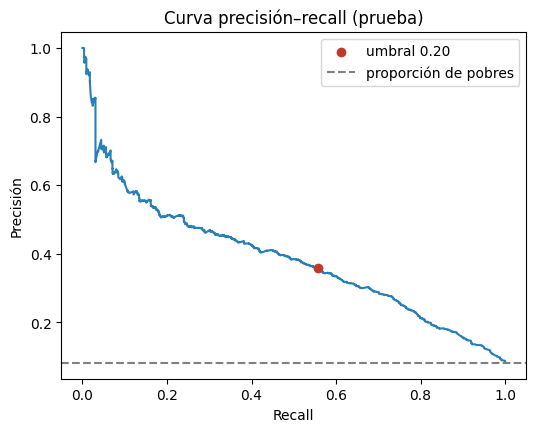

In [32]:
prec, rec, umb = precision_recall_curve(y_te, p_te, sample_weight=w_te)
i = np.argmin(np.abs(umb - UMBRAL))

plt.figure(figsize=(6, 4.5))
plt.plot(rec, prec, color="#2980b9")
plt.scatter(rec[i], prec[i], color="#c0392b", zorder=3, label=f"umbral {UMBRAL:.2f}")
plt.axhline(metricas["pr_auc_base"], color="gray", linestyle="--", label="proporción de pobres")
plt.title("Curva precisión–recall (prueba)")
plt.xlabel("Recall"); plt.ylabel("Precisión")
plt.legend()
plt.savefig(f"{REPORTES}/modelo_pr_curve.png", dpi=120, bbox_inches="tight")
plt.show()

### Predicho contra real por clase

Con el umbral escogido el modelo marca como pobres a más hogares de los que hay, porque prioriza encontrar a los pobres (recall) sobre no equivocarse (precisión). Lo revisamos por zona para saber qué esperar cuando el dashboard muestre el porcentaje de hogares marcados como pobres: esa cifra va a ser más alta que el porcentaje real.

In [33]:
t = pd.DataFrame({"clase": X_te["clase"].astype("Int64").astype("string"), "w": w_te,
                  "real": y_te * w_te, "predicho": pred_te * w_te})
por_clase = t.groupby("clase")[["real", "predicho", "w"]].sum()
por_clase["% pobres real"] = por_clase["real"] / por_clase["w"] * 100
por_clase["% marcados por el modelo"] = por_clase["predicho"] / por_clase["w"] * 100
por_clase.index = por_clase.index.map({"1": "1 Cabecera", "2": "2 Centro poblado", "3": "3 Rural disperso"})
por_clase[["% pobres real", "% marcados por el modelo"]].round(1)

,% pobres real,% marcados por el modelo
clase,,
1 Cabecera,4.8,5.6
2 Centro poblado,15.6,24.6
3 Rural disperso,21.4,43.2


In [ ]:
# hogares con y sin contexto de la GEIH (los 9 departamentos fuera de la GEIH no tienen
# pobreza monetaria, ingreso, ocupación ni educación superior). Los pct_* salen del CSV y
# siempre existen, por eso la máscara se arma con pobreza_monetaria y no con todo el contexto
sin_geih = X_te["pobreza_monetaria"].isna().values
filas = {}
for nombre, mask in {"con GEIH": ~sin_geih, "sin GEIH": sin_geih}.items():
    if y_te[mask].nunique() < 2:
        continue
    filas[nombre] = {
        "hogares": int(mask.sum()),
        "ROC-AUC": roc_auc_score(y_te[mask], p_te[mask], sample_weight=w_te[mask]),
        "PR-AUC": average_precision_score(y_te[mask], p_te[mask], sample_weight=w_te[mask]),
        "recall": recall_score(y_te[mask], pred_te[mask], sample_weight=w_te[mask]),
        "precisión": precision_score(y_te[mask], pred_te[mask], sample_weight=w_te[mask]),
    }
cobertura = pd.DataFrame(filas).T
display(cobertura.round(3))
metricas["roc_auc_sin_contexto"] = round(float(cobertura.loc["sin GEIH", "ROC-AUC"]), 4) if "sin GEIH" in cobertura.index else None

# calibración: probabilidad media predicha vs proporción real de pobres por decil
cal = pd.DataFrame({"p": p_te, "y": y_te.values, "w": w_te.values})
cal["decil"] = pd.qcut(cal["p"], 10, duplicates="drop")
tabla_cal = cal.groupby("decil").apply(lambda g: pd.Series({
    "prob. media predicha": np.average(g["p"], weights=g["w"]),
    "% real de pobres": np.average(g["y"], weights=g["w"]),
}))
display(tabla_cal.round(3))

ax = tabla_cal.plot(marker="o", figsize=(7, 4), title="Calibración por deciles (prueba)")
ax.set_xlabel("decil de probabilidad"); ax.set_ylabel("proporción")
plt.savefig(f"{REPORTES}/modelo_calibracion.png", dpi=120, bbox_inches="tight")
plt.show()

## Paso 9 — Departamentos que el modelo no vio

El split aleatorio mezcla hogares de todos los departamentos, así que el contexto departamental le sirve al modelo casi como un identificador del departamento. Para ver si de verdad generaliza, entrenamos sin el código del departamento y dejamos en prueba departamentos completos que no aparecen en el entrenamiento.

In [35]:
from sklearn.model_selection import GroupShuffleSplit

grupos = df.loc[X.index, "codigo_departamento"]
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEMILLA)
idx_tr, idx_te = next(gss.split(X, y, groups=grupos))

m_g = armar_pipe(TIPO, cat=fp.CAT_HOGAR)
m_g.fit(X.iloc[idx_tr], y.iloc[idx_tr], clf__sample_weight=w.iloc[idx_tr])
p_g = m_g.predict_proba(X.iloc[idx_te])[:, 1]

auc_grupos = roc_auc_score(y.iloc[idx_te], p_g, sample_weight=w.iloc[idx_te])
print(f"Departamentos en prueba: {grupos.iloc[idx_te].nunique()}")
print(f"ROC-AUC split aleatorio:       {metricas['roc_auc']:.3f}")
print(f"ROC-AUC departamentos nuevos:  {auc_grupos:.3f}")
print(f"Diferencia: {auc_grupos - metricas['roc_auc']:+.3f}")
metricas["roc_auc_departamentos_nuevos"] = round(float(auc_grupos), 4)

Departamentos en prueba: 9
ROC-AUC split aleatorio:       0.849
ROC-AUC departamentos nuevos:  0.811
Diferencia: -0.038


In [36]:
from IPython.display import Markdown, display

m = metricas
mejora_base = m["pr_auc"] / m["pr_auc_base"]
cae = m["roc_auc"] - m["roc_auc_departamentos_nuevos"]
mejor = max(cv_res, key=lambda k: cv_res[k]["PR-AUC media"])

display(Markdown(f"""### Discusión de resultados (prueba)
- **ROC-AUC {m['roc_auc']:.2f}:** el modelo ordena bien a los hogares pobres por encima de los no pobres.
- **PR-AUC {m['pr_auc']:.2f}** contra una línea base de {m['pr_auc_base']:.2f}: es unas **{mejora_base:.1f} veces** lo que daría el azar. La PR-AUC es la métrica más honesta aquí porque los pobres son pocos.
- **Umbral {m['umbral']:.2f}:** con recall {m['recall']:.2f} encuentra a la mayoría de los pobres, pero con precisión {m['precision']:.2f}. {"Menos de la mitad de los marcados son pobres" if m['precision'] < 0.5 else "La mayoría de los marcados son pobres"}, así que sirve para **priorizar** hogares y no para clasificarlos de forma definitiva.
- **Estabilidad:** en validación cruzada el modelo con mayor PR-AUC es {mejor}, y la desviación entre folds es pequeña ({cv_res[mejor]['PR-AUC desv.']:.3f}), así que el resultado no depende de un solo split.
- **Departamentos nuevos:** el ROC-AUC {"baja" if cae > 0 else "no baja"} {abs(cae):.2f} puntos respecto al split aleatorio ({m['roc_auc_departamentos_nuevos']:.2f}). {"El contexto departamental ayuda al modelo casi como un identificador." if cae > 0.03 else "El modelo generaliza bien a departamentos que no vio."}
"""))

### Discusión de resultados (prueba)
- **ROC-AUC 0.85:** el modelo ordena bien a los hogares pobres por encima de los no pobres.
- **PR-AUC 0.39** contra una línea base de 0.08: es unas **4.7 veces** lo que daría el azar. La PR-AUC es la métrica más honesta aquí porque los pobres son pocos.
- **Umbral 0.20:** con recall 0.56 encuentra a la mayoría de los pobres, pero con precisión 0.36. Menos de la mitad de los marcados son pobres, así que sirve para **priorizar** hogares y no para clasificarlos de forma definitiva.
- **Estabilidad:** en validación cruzada el modelo con mayor PR-AUC es HistGradientBoosting, y la desviación entre folds es pequeña (0.024), así que el resultado no depende de un solo split.
- **Departamentos nuevos:** el ROC-AUC baja 0.04 puntos respecto al split aleatorio (0.81). El contexto departamental ayuda al modelo casi como un identificador.


## Paso 10 — Importancia de las variables

Importancia por permutación sobre las columnas de entrada, calculada en una muestra de la prueba y medida como la caída del ROC-AUC al mezclar cada columna.

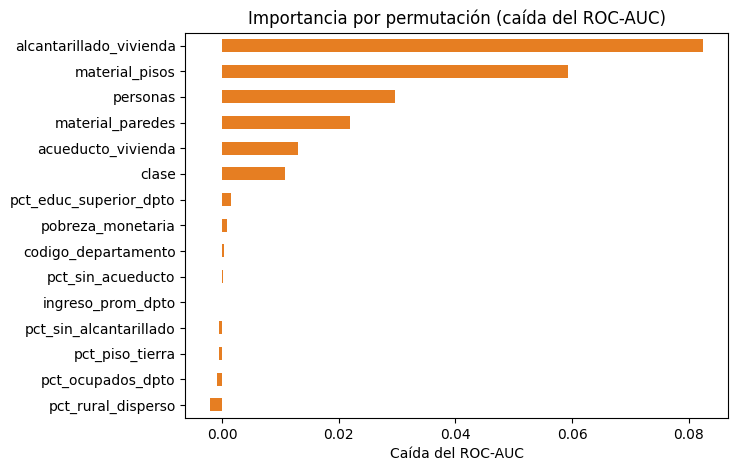

,0
alcantarillado_vivienda,0.0825
material_pisos,0.0593
personas,0.0296
material_paredes,0.0219
acueducto_vivienda,0.0130
clase,0.0108
pct_educ_superior_dpto,0.0015
pobreza_monetaria,0.0008
codigo_departamento,0.0003
pct_sin_acueducto,0.0002


In [37]:
from sklearn.inspection import permutation_importance

muestra = X_te.sample(min(5000, len(X_te)), random_state=SEMILLA)
r = permutation_importance(modelo_final, muestra, y_te.loc[muestra.index],
                           scoring="roc_auc", n_repeats=5, random_state=SEMILLA,
                           sample_weight=w_te.loc[muestra.index], n_jobs=1)

imp = pd.Series(r.importances_mean, index=fp.COLS_ENTRADA).sort_values()
plt.figure(figsize=(7, 5))
imp.plot(kind="barh", color="#e67e22")
plt.title("Importancia por permutación (caída del ROC-AUC)")
plt.xlabel("Caída del ROC-AUC")
plt.savefig(f"{REPORTES}/modelo_importancia.png", dpi=120, bbox_inches="tight")
plt.show()
imp.sort_values(ascending=False).round(4)

## Paso 11 — Guardar el modelo

Guardamos el pipeline completo (preparación, preprocesamiento y modelo) en un solo archivo, junto con un JSON que dice con qué se entrenó: columnas de entrada, umbral, métricas y versiones de las librerías. Si el consumer corre con otra versión de scikit-learn, el JSON es lo primero que hay que mirar. También guardamos unos eventos de ejemplo, con el mismo formato que va a publicar el productor, y copiamos `features_pobreza.py` a la carpeta del modelo. Además dejamos `ids_streaming.csv` con los `id_hogar` de la prueba: el productor de Kafka tiene que publicar solo esos hogares, porque el resto se usó para entrenar y las predicciones sobre ellos saldrían mejores de lo que son.

In [ ]:
import joblib, sklearn

RUTA_MODELO = f"{MODELOS}/modelo_pobreza.joblib"

# archivo de una versión anterior del notebook: el consumer solo usa modelo_pobreza.joblib
antiguo = f"{MODELOS}/modelo_pobreza_hgb.joblib"
if os.path.exists(antiguo):
    os.remove(antiguo)
    print("Borrado archivo antiguo:", os.path.basename(antiguo))

joblib.dump(modelo_final, RUTA_MODELO)
shutil.copy(f"{SRC}/features_pobreza.py", f"{MODELOS}/features_pobreza.py")

with open(RUTA_MODELO, "rb") as f:
    huella = hashlib.sha256(f.read()).hexdigest()

meta = {
    "modelo": NOMBRES[TIPO],
    "target": TARGET,
    "descripcion_target": "1 si el hogar es pobre según el IPM",
    "peso_entrenamiento": PESO,
    "id_evento": "id_hogar",
    "columnas_entrada": fp.COLS_ENTRADA,
    "features_cat": CAT,
    "features_num": NUM,
    "excluidas_a_proposito": ["pobre", "ipm", "fex_c", "hogares_db", "incidencia_ipm", "ipm_promedio"],
    "umbral": UMBRAL,
    "metricas_prueba": metricas,
    "filas_entrenamiento": int(len(X_tr)),
    "filas_prueba": int(len(X_te)),
    "semilla": SEMILLA,
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
    "sha256_modelo": huella,
}
with open(f"{MODELOS}/modelo_pobreza_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

# eventos de ejemplo: id del hogar y columnas de entrada, sin pobre ni ipm
ej = X_te.head(20)
eventos = pd.concat([df.loc[ej.index, ["id_hogar"]], ej], axis=1)
eventos_json = json.loads(eventos.to_json(orient="records", double_precision=15))
with open(f"{MODELOS}/eventos_ejemplo.json", "w", encoding="utf-8") as f:
    json.dump(eventos_json, f, indent=2, ensure_ascii=False)

# hogares que el modelo no vio: los unicos que debe publicar el productor
RUTA_IDS = f"{MODELOS}/ids_streaming.csv"
df.loc[X_te.index, ["id_hogar"]].to_csv(RUTA_IDS, index=False)
meta["ids_streaming"] = {"archivo": "ids_streaming.csv", "hogares": int(len(X_te))}
with open(f"{MODELOS}/modelo_pobreza_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)
print(f"Hogares para el streaming: {len(X_te):,} ({len(X_te) / len(df):.0%} del dataset)")

print("Guardado en", MODELOS)
print(os.listdir(MODELOS))

### Paso 11b — Guardar la partición en el warehouse

Además de `ids_streaming.csv`, dejamos la partición completa en la tabla `split_modelo` de la base donde cargó el DAG: una fila por hogar, con su `id_hogar`, el grupo al que pertenece (`entrenamiento`, `validacion` o `prueba`) y la huella del modelo con el que se hizo. El modelo final se entrena con entrenamiento y validación juntos (Paso 8); la prueba no se toca.

Así el productor puede leer los hogares de prueba con un `JOIN` a la vista del dataset, y el reporte puede cruzar las predicciones con el `pobre` real sin depender de un archivo suelto.

La tabla es independiente de las del DAG. Si no hay base (por ejemplo, se reinició el SQLite de Colab) o falla la escritura, el notebook avisa y la partición sigue en `ids_streaming.csv`. Si el DAG se vuelve a ejecutar con datos distintos, hay que volver a correr este notebook para regenerarla.


In [ ]:
from sqlalchemy import create_engine, text

TABLA_SPLIT = "split_modelo"

# una fila por hogar: entrenamiento y validación (con los que se escogió el modelo) y prueba
split = pd.concat([
    pd.DataFrame({"id_hogar": df.loc[X_sub.index, "id_hogar"].values, "split": "entrenamiento"}),
    pd.DataFrame({"id_hogar": df.loc[X_val.index, "id_hogar"].values, "split": "validacion"}),
    pd.DataFrame({"id_hogar": df.loc[X_te.index, "id_hogar"].values, "split": "prueba"}),
], ignore_index=True)
split["modelo"] = NOMBRES[TIPO]
split["sha256_modelo"] = huella
split["fecha_entrenamiento"] = meta["fecha_entrenamiento"]

# revisiones antes de escribir: cada hogar en un solo grupo y la prueba igual a ids_streaming.csv
assert split["id_hogar"].is_unique, "hay hogares en más de un grupo"
assert len(split) == len(df), "la partición no cubre todos los hogares"
assert set(split.loc[split["split"] == "prueba", "id_hogar"]) == set(pd.read_csv(RUTA_IDS)["id_hogar"]), \
    "la prueba no coincide con ids_streaming.csv"
print(split["split"].value_counts().to_string())

url_destino = secreto("DESTINO_URL")
if not url_destino:
    print("[split_modelo] No hay DESTINO_URL: la partición queda solo en ids_streaming.csv.")
else:
    try:
        motor_split = create_engine(url_destino)
        metodo = "multi" if motor_split.dialect.name == "postgresql" else None
        split.to_sql(TABLA_SPLIT, motor_split, if_exists="replace", index=False, chunksize=2000, method=metodo)
        with motor_split.begin() as con:
            con.execute(text(f"CREATE UNIQUE INDEX IF NOT EXISTS ix_{TABLA_SPLIT}_id_hogar ON {TABLA_SPLIT} (id_hogar)"))

        n_split = int(pd.read_sql_query(f"SELECT COUNT(*) AS n FROM {TABLA_SPLIT}", motor_split)["n"].iloc[0])
        if n_split != len(split):
            raise ValueError(f"se guardaron {n_split:,} filas y eran {len(split):,}")

        # todos los hogares de la partición tienen que existir en la tabla de hechos del DAG
        sin_hecho = int(pd.read_sql_query(
            f"SELECT COUNT(*) AS n FROM {TABLA_SPLIT} s LEFT JOIN fact_hogar_ipm f ON s.id_hogar = f.id_hogar "
            f"WHERE f.id_hogar IS NULL", motor_split)["n"].iloc[0])
        if sin_hecho:
            print(f"[split_modelo] Ojo: {sin_hecho:,} hogares de la partición no están en fact_hogar_ipm; "
                  "el DAG se ejecutó con otros datos. Volver a entrenar con el dataset actual.")

        meta["split_en_warehouse"] = {"tabla": TABLA_SPLIT, "filas": n_split}
        with open(f"{MODELOS}/modelo_pobreza_meta.json", "w", encoding="utf-8") as f:
            json.dump(meta, f, indent=2, ensure_ascii=False)
        print(f"[split_modelo] guardada en la base: {n_split:,} filas")
    except Exception as e:
        print(f"[split_modelo] No se pudo guardar en la base ({type(e).__name__}: {e}). "
              "La partición sigue en ids_streaming.csv; el resto del notebook no se afecta.")


## Paso 12 — Prueba de lectura como la hará el consumer

Cargamos el archivo desde el disco, armamos un `DataFrame` con los eventos de ejemplo tal como saldrían del JSON de Kafka y comparamos las probabilidades con las que da el modelo que está en memoria. Después probamos un evento con valores nulos, que es lo que pasa con los hogares de los departamentos sin contexto.

Para que esta prueba se parezca a lo que va a pasar de verdad, el consumer tiene que hacer exactamente esto: importar `features_pobreza`, cargar el `.joblib` una sola vez al arrancar y llamar `predict_proba` por cada mensaje.

In [39]:
cargado = joblib.load(RUTA_MODELO)
with open(f"{MODELOS}/modelo_pobreza_meta.json", encoding="utf-8") as f:
    meta_leida = json.load(f)

ev = pd.DataFrame(eventos_json)
p_evento = cargado.predict_proba(ev[meta_leida["columnas_entrada"]])[:, 1]
p_memoria = modelo_final.predict_proba(ej)[:, 1]
assert np.allclose(p_evento, p_memoria, atol=1e-6), "el modelo cargado da otras probabilidades"
print(f"[ok] {len(ev)} eventos: el modelo cargado coincide con el de memoria")

# un solo mensaje, con nulos, como lo vería el consumer
mensaje = dict(eventos_json[0])
mensaje["pobreza_monetaria"] = None
mensaje["material_pisos"] = None
p1 = cargado.predict_proba(pd.DataFrame([mensaje])[meta_leida["columnas_entrada"]])[:, 1][0]
print(f"[ok] mensaje con nulos: probabilidad {p1:.3f} -> "
      f"{'pobre' if p1 >= meta_leida['umbral'] else 'no pobre'} (umbral {meta_leida['umbral']:.3f})")

[ok] 20 eventos: el modelo cargado coincide con el de memoria
[ok] mensaje con nulos: probabilidad 0.228 -> pobre (umbral 0.198)


## Paso 13 — Limitaciones

El modelo se entrenó con una sola encuesta y una sola fecha de corte, así que no sabemos cómo se comporta con datos de otro año. Las cuatro variables de vivienda son insumo directo de indicadores del IPM; eso explica por qué son las que más pesan y por qué el modelo funciona mejor para describir la pobreza multidimensional que para anticipar un cambio futuro en un hogar. No sirve para decir por qué un hogar es pobre, solo qué tan parecido es a los hogares que la encuesta clasificó como pobres.

El contexto departamental falta para los 9 departamentos que no están en la GEIH (alrededor del 21% de los hogares). En esos hogares faltan las cuatro variables que vienen de la GEIH (pobreza monetaria, ingreso, ocupación y educación superior); el modelo conserva las de vivienda y los porcentajes que salen del CSV. Medimos aparte qué tan bien le va ahí en el Paso 8 (filas «con GEIH» y «sin GEIH»). Con departamentos que nunca vio el ROC-AUC baja respecto al split aleatorio, así que las predicciones para un departamento nuevo hay que leerlas con más cuidado.

Las probabilidades salen de un modelo entrenado con el peso `fex_c`, por lo que el umbral está pensado para la prevalencia de la población (8.3%) y no para la de la muestra (14.2%). Como el umbral prioriza el recall, el porcentaje de hogares que el dashboard marque como pobres va a ser mayor que el porcentaje real de pobres. Y la precisión de la clase pobre es baja (menos de la mitad de los marcados son pobres), por lo que el resultado sirve para priorizar hogares y no para clasificarlos de forma definitiva.

Por último, el archivo `.joblib` depende de la versión de scikit-learn con que se entrenó. Las versiones quedaron en el JSON de metadatos y hay que fijarlas en el `requirements.txt` del consumer.